# Exploring the NeurWIN deadline-scheduling replication

A charging station has **N** spots and power for **M** cars per round. Each car announces how many rounds it will stay (**T**) and how much charge it needs (**B**). Every round the station gives each car a score and charges the M highest.

Two ways to get the score are compared here:

- the **closed-form Whittle index**, an exact formula known for this problem;
- **NeurWIN**, a small neural network that learns the score by trial and error.

The number reported everywhere is the *total discounted reward* of a 300-round episode (higher is better; it is negative because unfinished cars cost a penalty).

**How to use this notebook:** change the settings in the first code cell, then choose *Run All*. In VS Code, pick the repo's `.venv` as the kernel.

## Settings

Everything you might want to change is in this one cell, and every cell below reads it. Each cell's output starts with a `Settings used:` line so you can see which settings produced it.

- `N`, `M`, `RUNS`, `STRIDE` control testing in every chart.
- `SIZES` lists the station sizes for the scaling chart; the current `(N, M)` is always added.
- `COMPARE_EXP` names an existing experiment in `trainResults/experiments/` to draw over the replication curve (`None` = skip). It is tested again at the current settings each time.
- The `RETRAIN` block is only used if you set `RETRAIN = True`; training 2,000 episodes takes about 3 minutes.

In [1]:
N = 4            # number of charging spots (arms)
M = 1            # how many cars can be charged per round (1 <= M <= N)
RUNS = 50        # test episodes to average over (the paper uses 50)
STRIDE = 50      # test every STRIDE-th saved checkpoint: 50 means episodes 0, 50, 100, ..., 2000

SIZES = [(4, 1), (8, 2), (20, 5)]   # (N, M) pairs for the scaling chart; the current (N, M) is always added
COMPARE_EXP = "m5"       # existing experiment to overlay on the replication curve; None = skip

RETRAIN = False          # True = also train a new network with the settings below and overlay it
EXP_NAME = "m5"              # folder name for the new run: trainResults/experiments/<EXP_NAME>/
EPISODES = 2000          # how many training episodes
SIGMOID_M = 5            # the sigmoid sensitivity "m" in NeurWIN's training (the paper uses 1 here)
SEED = 50                # random seed for training (the replication used 50)


def settings_used(**extra):
    """Print the one-line summary of the settings a cell ran with."""
    parts = [f"N={N}", f"M={M}", f"RUNS={RUNS}", f"STRIDE={STRIDE}"]
    parts += [f"{k}={v!r}" for k, v in extra.items()]
    print("Settings used: " + ", ".join(parts))


settings_used(SIZES=SIZES, COMPARE_EXP=COMPARE_EXP, RETRAIN=RETRAIN)

Settings used: N=4, M=1, RUNS=50, STRIDE=50, SIZES=[(4, 1), (8, 2), (20, 5)], COMPARE_EXP='m5', RETRAIN=False


## Load the helper functions

This finds `explore_lib.py` (next to this notebook) and imports it. The library uses the authors' own network, training and environment classes without changing them.

In [2]:
settings_used()

import sys
from pathlib import Path

# explore_lib.py sits next to this notebook; look in the usual places a notebook is started from
for folder in (Path.cwd(), Path.cwd() / "replication", Path.cwd() / "NeurWIN" / "replication"):
    if (folder / "explore_lib.py").exists():
        sys.path.insert(0, str(folder))
        break
else:
    raise FileNotFoundError("explore_lib.py not found: open this notebook from NeurWIN/replication")

import explore_lib as lab
print("NeurWIN folder:", lab.REPO)

Settings used: N=4, M=1, RUNS=50, STRIDE=50


NeurWIN folder: /Users/aidenlee/orca/Restless-Bandit/NeurWIN


## The existing trained model

This tests the network trained for the replication (`trainResults/neurwin/deadline_env/`) at every `STRIDE`-th checkpoint, and the closed-form index on the same test episodes.

In the chart, the solid line is NeurWIN's average reward as training goes on, the shaded band covers the middle 90% of test runs, and the dashed line is the closed-form index. With the default settings the last point should be **-99.3** and the index **-105.1**.

Settings used: N=4, M=1, RUNS=50, STRIDE=50


tested 41 checkpoints (episodes 0 to 2000) and the index: N=4, M=1, 50 runs each, 16 s


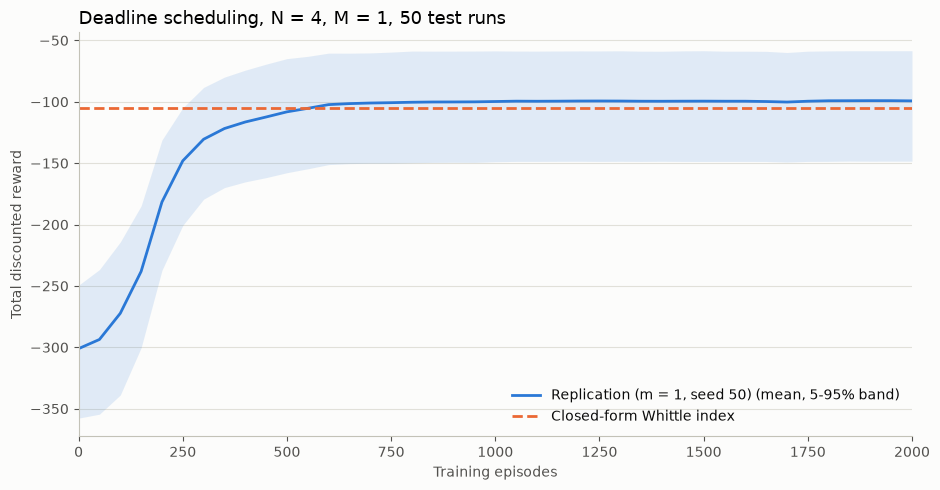

                  experiment  N  M  last episode  NeurWIN   index  NeurWIN - index  std. error NeurWIN better in  first tested episode >= index
Replication (m = 1, seed 50)  4  1          2000   -99.25 -105.05              5.8        0.35             50/50                            600


In [3]:
settings_used()

existing = lab.evaluate(lab.DEFAULT_MODEL_DIR, N=N, M=M, runs=RUNS, stride=STRIDE)
existing.attrs["stride"] = STRIDE
lab.plot_curve([existing], ["Replication (m = 1, seed 50)"])

## Train a new network and compare

This draws other networks over the replication curve, all tested at the current `N`, `M`, `RUNS` and `STRIDE`:

- if `RETRAIN = True`, a fresh network is trained with the `RETRAIN` settings and saved to `trainResults/experiments/<EXP_NAME>/` (the replication's checkpoints are never touched; running again with the same name and settings reuses the saved checkpoints);
- if `COMPARE_EXP` names an existing experiment, its saved checkpoints are tested again and drawn too.

Only checkpoints are reused. Test results are always recomputed, so the chart never shows numbers from older settings.

Settings used: N=4, M=1, RUNS=50, STRIDE=50, RETRAIN=False, EXP_NAME='m5', COMPARE_EXP='m5'


tested 41 checkpoints (episodes 0 to 2000) and the index: N=4, M=1, 50 runs each, 16 s


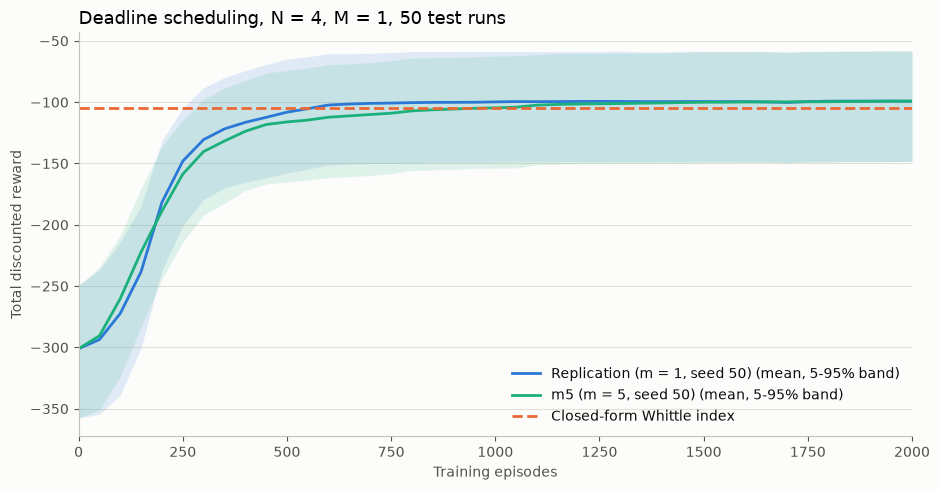

                  experiment  N  M  last episode  NeurWIN   index  NeurWIN - index  std. error NeurWIN better in  first tested episode >= index
Replication (m = 1, seed 50)  4  1          2000   -99.25 -105.05             5.80        0.35             50/50                            600
         m5 (m = 5, seed 50)  4  1          2000   -99.08 -105.05             5.97        0.36             50/50                            950


In [4]:
import os, json

settings_used(RETRAIN=RETRAIN, EXP_NAME=EXP_NAME, COMPARE_EXP=COMPARE_EXP)


def describe(folder, name):
    """Chart label from an experiment's settings.json, e.g. 'm5 (m = 5, seed 50)'."""
    try:
        with open(os.path.join(folder, "settings.json")) as f:
            s = json.load(f)
        return f"{name} (m = {s['sigmoid_m']:g}, seed {s['seed']})"
    except (OSError, KeyError, ValueError):
        return name


# The replication curve from the cell above, re-tested if it was made with other settings
# (for example if the settings changed and only this cell was run).
if (existing.attrs.get("N"), existing.attrs.get("M"), existing.attrs.get("runs"),
        existing.attrs.get("stride")) != (N, M, RUNS, STRIDE):
    print("The replication result in memory used other settings; testing it again.")
    existing = lab.evaluate(lab.DEFAULT_MODEL_DIR, N=N, M=M, runs=RUNS, stride=STRIDE)
    existing.attrs["stride"] = STRIDE

curves, labels = [existing], ["Replication (m = 1, seed 50)"]

if RETRAIN:
    new_dir = lab.train(EXP_NAME, episodes=EPISODES, sigmoid_m=SIGMOID_M, seed=SEED, save_every=STRIDE)
    curves.append(lab.evaluate(new_dir, N=N, M=M, runs=RUNS, stride=STRIDE))
    labels.append(describe(new_dir, EXP_NAME))

if COMPARE_EXP is not None and not (RETRAIN and COMPARE_EXP == EXP_NAME):   # don't draw the same run twice
    compare_dir = os.path.join(lab.EXPERIMENT_DIR, COMPARE_EXP)
    if os.path.isdir(compare_dir):
        curves.append(lab.evaluate(compare_dir, N=N, M=M, runs=RUNS, stride=STRIDE))
        labels.append(describe(compare_dir, COMPARE_EXP))
    else:
        print(f"COMPARE_EXP = {COMPARE_EXP!r} not found in {lab.EXPERIMENT_DIR}, so it was skipped.")

if len(curves) > 1:
    lab.plot_curve(curves, labels)
else:
    print("Nothing to compare: set RETRAIN = True or COMPARE_EXP to an existing experiment.")

## Does the result hold for other station sizes?

The same trained network is tested on every size in `SIZES`, plus the current `(N, M)` from the settings cell. Each bar is NeurWIN's reward minus the index's, as a percentage of the index. Above zero means NeurWIN did better.

Settings used: N=4, M=1, RUNS=50, STRIDE=50, SIZES=[(4, 1), (8, 2), (20, 5)]


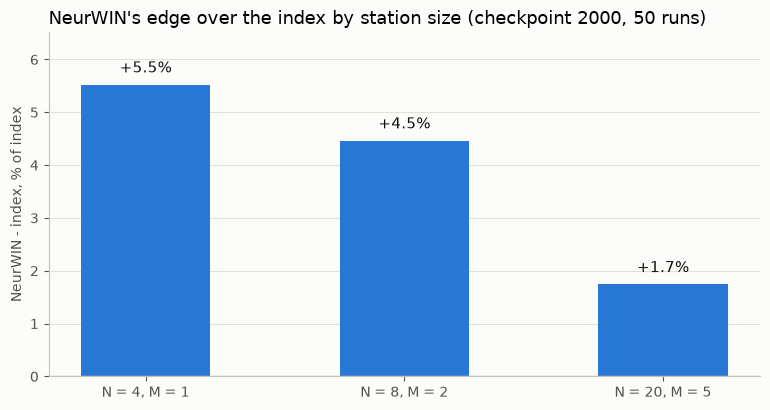

 N  M  NeurWIN   index  NeurWIN - index  % of index  std. error NeurWIN better in
 4  1   -99.25 -105.05             5.80        5.52        0.35             50/50
 8  2  -185.75 -194.41             8.67        4.46        0.50             50/50
20  5  -451.57 -459.56             7.98        1.74        0.55             49/50


In [5]:
sizes = sorted(set(SIZES) | {(N, M)})     # always include the current station
settings_used(SIZES=sizes)

lab.plot_scaling(lab.DEFAULT_MODEL_DIR, sizes=sizes, runs=RUNS)

## What the network actually learned

Both policies are just a score for each state (T, B). The left grid is NeurWIN's learned score and the right grid is the closed-form index, on the same color scale: darker means "charge this car first". Rows are T (rounds until the car leaves), columns are B (charge still needed). In row T = 0 only the first cell (an empty spot) can actually occur.

Settings used: N=4, M=1, RUNS=50, STRIDE=50


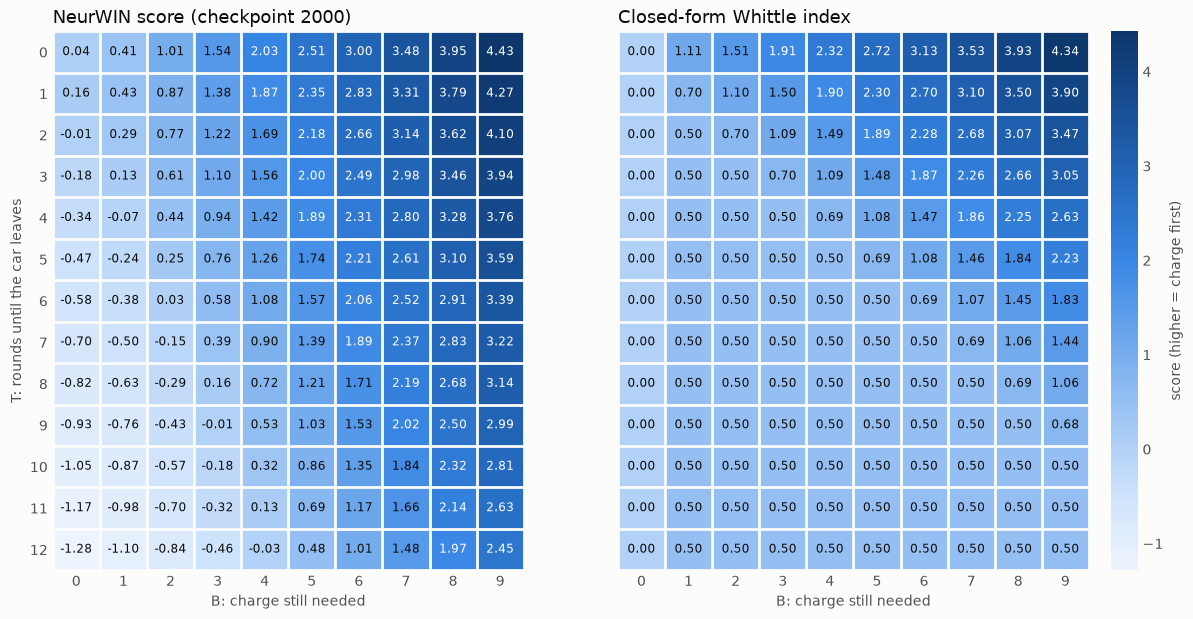

Over the 108 states with a car that still needs charge (T >= 1, B >= 1):
  correlation of the two scores: 0.729   rank correlation: 0.737
  mean absolute difference: 0.85
  largest differences:
 T  B  NeurWIN  index  NeurWIN - index
10  9     2.81   0.50             2.31
 9  9     2.99   0.68             2.31
11  9     2.63   0.50             2.13
 8  9     3.14   1.06             2.08
 9  8     2.50   0.50             2.00


In [6]:
settings_used()

lab.plot_score_tables(lab.DEFAULT_MODEL_DIR)